In [1]:
import time, json, warnings
import numpy as np, pandas as pd
from pathlib import Path
warnings.filterwarnings("ignore")
from xgboost import XGBClassifier           # !pip install xgboost
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, matthews_corrcoef, confusion_matrix)

P = Path("processed"); B = P / "balanced"
X_val = np.load(P / "X_val.npy"); y_val = np.load(P / "y_val.npy")

sets = ["none", "class_weight", "random_over", "random_under", "smote",
        "borderline_smote", "adasyn", "under_then_smote",
        "smote_tomek", "smote_enn", "tomek_links"]

In [2]:
rows, cms = [], {}
for s in sets:
    d = np.load(B / ("none.npz" if s == "class_weight" else f"{s}.npz"))
    X, y = d["X"], d["y"]
    spw = (y == 0).sum() / (y == 1).sum() if s == "class_weight" else 1.0

    m = XGBClassifier(n_estimators=100, learning_rate=0.3, max_depth=6,
                      tree_method="hist", scale_pos_weight=spw,
                      eval_metric="logloss", n_jobs=-1, random_state=42)
    t = time.time(); m.fit(X, y); fit_s = time.time() - t

    pred = m.predict(X_val); prob = m.predict_proba(X_val)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    cms[s] = [[int(tn), int(fp)], [int(fn), int(tp)]]
    rows.append({
        "set": s, "train_rows": len(y),
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred),
        "recall_attack": recall_score(y_val, pred),
        "normal_recall": tn / (tn + fp),
        "f1": f1_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "pr_auc": average_precision_score(y_val, prob),
        "roc_auc": roc_auc_score(y_val, prob),
        "mcc": matthews_corrcoef(y_val, pred),
        "FPR": fp / (fp + tn), "FNR": fn / (fn + tp), "fit_s": fit_s})
    print(s, "done")

results = pd.DataFrame(rows).sort_values("mcc", ascending=False)
results.round(4)

none done
class_weight done
random_over done
random_under done
smote done
borderline_smote done
adasyn done
under_then_smote done
smote_tomek done
smote_enn done
tomek_links done


,set,train_rows,accuracy,precision,recall_attack,normal_recall,f1,macro_f1,pr_auc,roc_auc,mcc,FPR,FNR,fit_s
0,none,140311,0.9949,0.9943,0.9998,0.9635,0.9971,0.9890,0.9997,0.9985,0.9782,0.0365,0.0002,2.0369
10,tomek_links,140193,0.9949,0.9945,0.9996,0.9647,0.9970,0.9889,0.9998,0.9985,0.9780,0.0353,0.0004,1.4601
4,smote,242568,0.9944,0.9953,0.9983,0.9701,0.9968,0.9881,0.9997,0.9983,0.9762,0.0299,0.0017,2.4123
8,smote_tomek,242092,0.9944,0.9954,0.9981,0.9708,0.9968,0.9879,0.9997,0.9983,0.9759,0.0292,0.0019,2.5473
9,smote_enn,236452,0.9932,0.9951,0.9971,0.9688,0.9961,0.9855,0.9996,0.9979,0.9711,0.0312,0.0029,2.5141
1,class_weight,140311,0.9923,0.9955,0.9955,0.9715,0.9955,0.9835,0.9997,0.9984,0.9671,0.0285,0.0045,1.5271
7,under_then_smote,76108,0.9923,0.9955,0.9956,0.9711,0.9955,0.9835,0.9997,0.9985,0.9671,0.0289,0.0044,0.8455
2,random_over,242568,0.9921,0.9953,0.9955,0.9703,0.9954,0.9832,0.9997,0.9984,0.9664,0.0297,0.0045,2.4501
3,random_under,38054,0.9891,0.9960,0.9913,0.9747,0.9937,0.9770,0.9997,0.9983,0.9541,0.0253,0.0087,0.5741
5,borderline_smote,242568,0.9807,0.9964,0.9812,0.9774,0.9888,0.9605,0.9996,0.9978,0.9223,0.0226,0.0188,2.6352


In [3]:
results.round(4).to_csv(P / "xgb_results.csv", index=False)
json.dump(cms, open(P / "xgb_confusion.json", "w"))

In [4]:
lr = pd.read_csv(P / "lr_results.csv").set_index("set")
sv = pd.read_csv(P / "svm_results.csv").set_index("set")
xg = results.set_index("set")
cmp = pd.DataFrame({"LR_mcc": lr["mcc"], "SVM_mcc": sv["mcc"], "XGB_mcc": xg["mcc"],
                    "LR_FNR": lr["FNR"], "SVM_FNR": sv["FNR"], "XGB_FNR": xg["FNR"]}).round(4)
cmp.sort_values("XGB_mcc", ascending=False)

,LR_mcc,SVM_mcc,XGB_mcc,LR_FNR,SVM_FNR,XGB_FNR
set,,,,,,
none,0.8351,0.8269,0.9782,0.0124,0.0128,0.0002
tomek_links,0.8351,0.8269,0.9780,0.0127,0.0128,0.0004
smote,0.7381,0.7386,0.9762,0.0779,0.0756,0.0017
smote_tomek,0.7387,0.7402,0.9759,0.0776,0.0748,0.0019
smote_enn,0.7469,0.7460,0.9711,0.0728,0.0711,0.0029
class_weight,0.7372,0.7376,0.9671,0.0784,0.0768,0.0045
under_then_smote,0.7320,0.7358,0.9671,0.0810,0.0780,0.0044
random_over,0.7387,0.7382,0.9664,0.0777,0.0754,0.0045
random_under,0.7309,0.7340,0.9541,0.0813,0.0788,0.0087


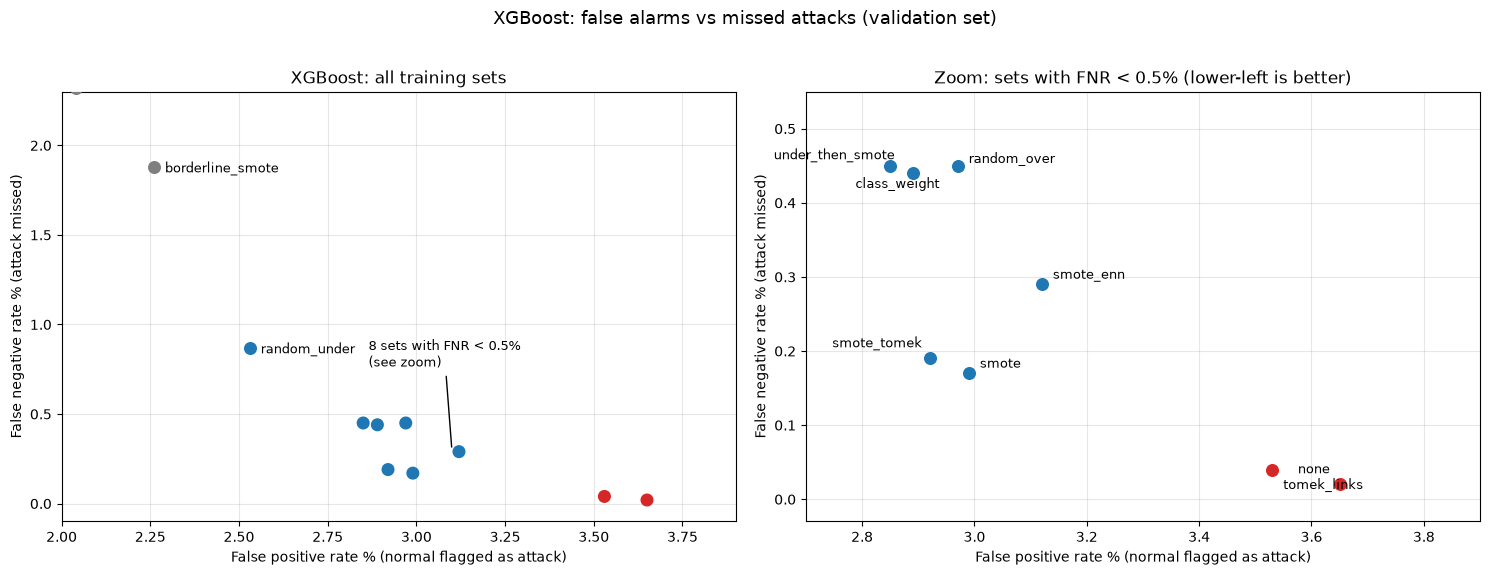

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

r = pd.read_csv(P / "xgb_results.csv")
col = {"none": "tab:red", "tomek_links": "tab:red",
       "borderline_smote": "tab:gray", "adasyn": "tab:gray"}

def draw(a, d, title, offs):
    for _, x in d.iterrows():
        a.scatter(x["FPR"] * 100, x["FNR"] * 100, s=70,
                  color=col.get(x["set"], "tab:blue"), zorder=3)
        a.annotate(x["set"], (x["FPR"] * 100, x["FNR"] * 100),
                   xytext=offs.get(x["set"], (6, 6)), textcoords="offset points", fontsize=9)
    a.set_xlabel("False positive rate % (normal flagged as attack)")
    a.set_ylabel("False negative rate % (attack missed)")
    a.set_title(title); a.grid(alpha=.3)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
big = r[r["set"].isin(["adasyn", "borderline_smote", "random_under"])]
mid = r[~r["set"].isin(["adasyn", "borderline_smote", "random_under"])]

# left: all sets, labelling only the outliers
draw(ax[0], big, "XGBoost: all training sets",
     {"adasyn": (8, -4), "borderline_smote": (8, -4), "random_under": (8, -4)})
ax[0].scatter(mid["FPR"] * 100, mid["FNR"] * 100, s=70,
              color=[col.get(s, "tab:blue") for s in mid["set"]], zorder=3)
ax[0].annotate("8 sets with FNR < 0.5%\n(see zoom)", (3.1, 0.3), xytext=(-60, 60),
               textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-"))
ax[0].set_xlim(2.0, 3.9); ax[0].set_ylim(-0.1, 2.3)

# right: zoom on the low-FNR sets
offs = {"none": (-30, 8), "tomek_links": (8, -14), "smote_tomek": (-70, 8),
        "smote": (8, 4), "smote_enn": (8, 4), "under_then_smote": (-100, 10),
        "class_weight": (-25, -16), "random_over": (8, 2)}
draw(ax[1], mid, "Zoom: sets with FNR < 0.5% (lower-left is better)", offs)
ax[1].set_xlim(2.7, 3.9); ax[1].set_ylim(-0.03, 0.55)

fig.suptitle("XGBoost: false alarms vs missed attacks (validation set)", fontsize=13)
plt.tight_layout(rect=[0, .03, 1, .96])
plt.savefig(P / "xgb_tradeoff.png", dpi=150); plt.show()